# DS-A5 | Time-Series Rolling Evaluation Lab

**Name:** Kseniia Mamushkina  
**Student ID:** 2026A8010351001  
**Course:** Data Science

## 1. Forecasting task and data availability

### Research question

How accurately can next-month counts of Black-faced Spoonbills (*Platalea minor*) in Deep Bay, southern China, be predicted using previous monthly counts?

### Conservation significance and study area

The Black-faced Spoonbill is a globally threatened waterbird. The latest IUCN assessment, published in 2025, classifies it as Vulnerable (VU), following its downlisting from Endangered [1].

Deep Bay, also known as Shenzhen Bay, lies between northwestern Hong Kong and Shenzhen in southern China. It is an internationally important wintering site for this species.

Forecasting seasonal changes in recorded counts could help managers plan monitoring activities and identify observations that warrant further investigation.

### Stakeholders and operational scenario

The intended stakeholders are wetland managers and the waterbird monitoring team.

In the proposed scenario, the team uses the information available at the end of each month to forecast the count for the following month. Once the next monthly count becomes available, the forecast is evaluated and the observation is added to the historical record.

This is a proposed application scenario, not a documented request from a management organisation.

### Data sources and reliability

The dataset contains **60 consecutive monthly counts from April 2018 to March 2023**. It was compiled from ten summer and winter reports of the **Mai Po Inner Deep Bay Ramsar Site Waterbird Monitoring Programme**, prepared by the Hong Kong Bird Watching Society (HKBWS) for the Agriculture, Fisheries and Conservation Department (AFCD), Hong Kong SAR Government [2–3].

The source tables are publicly accessible through the official HKBWS report archives. The CSV used here is a derived dataset assembled from those tables, rather than an official HKBWS CSV download. Each row retains the source report, page number, and URL.

The programme uses coordinated monthly surveys conducted by trained surveyors. Sites are surveyed simultaneously as far as possible to reduce double-counting. Monthly totals may incorporate supplementary observations. Detectability, bird movements, and survey conditions can nevertheless affect the recorded counts [2–3].

All 60 extracted values were checked against the reports, and a subset was independently checked by the student. The series has no missing months and includes seven confirmed zero counts. A zero means that no birds were recorded, rather than proving their complete absence.

### Target variable

The target is the number of Black-faced Spoonbills expected to be recorded during the monthly survey in the Deep Bay Area in the following month.

### Information availability

For this operational simulation, each monthly count is assumed to be available internally by the end of its corresponding month. The published counts are used as proxies for those internal records.

A forecast for month t+1 may use counts from month t and earlier, together with calendar information known in advance. The observed count for month t+1 and all later observations must remain unavailable when producing that forecast.

### Sources

[1] BirdLife International (2025). *Platalea minor*. The IUCN Red List of Threatened Species.
https://doi.org/10.2305/IUCN.UK.2025-2.RLTS.T22697568A154689773.en

[2] HKBWS. *Monthly Waterbird Monitoring: summer report archive*. Reports used: 2018–2022.
https://cms.hkbws.org.hk/cms/en/component/phocadownload/category/14-research-report/15-mai-po-inner-deep-bay-ramsar-site-waterbird-monitoring-programme/24-reports-of-monthly-waterbird-monitoring/27-wmp-summer-report?Itemid=674

[3] HKBWS. *Monthly Waterbird Monitoring: winter report archive*. Reports used: 2018–2019 through 2022–2023.
https://cms.hkbws.org.hk/cms/en/component/phocadownload/category/14-research-report/15-mai-po-inner-deep-bay-ramsar-site-waterbird-monitoring-programme/24-reports-of-monthly-waterbird-monitoring/26-wmp-winter-report?Itemid=674

Sources accessed: 23 November 2026.

### 1.1. Loading the dataset

The compiled monthly dataset is loaded from a CSV file. Its SHA-256 hash is recorded to identify the exact data version used in this analysis.

In [2]:
import io
import hashlib
import pandas as pd
from google.colab import files

# Upload the compiled CSV dataset
uploaded = files.upload()

if len(uploaded) != 1:
    raise ValueError("Please upload exactly one CSV file.")

filename = next(iter(uploaded))
raw_data = uploaded[filename]

# Record the exact file version
data_sha256 = hashlib.sha256(raw_data).hexdigest()

# Read the dataset
df = pd.read_csv(io.BytesIO(raw_data))

print("File:", filename)
print("SHA-256:", data_sha256)
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("\nColumn names:")
print(df.columns.tolist())

# Inspect the first ten monthly observations
display(df[["month", "survey_date", "count"]].head(10))

Saving deepbay_black_faced_spoonbill_monthly_2018_2023.csv to deepbay_black_faced_spoonbill_monthly_2018_2023.csv
File: deepbay_black_faced_spoonbill_monthly_2018_2023.csv
SHA-256: 4094b12afb2722e1690d39e62d95221aaef6f1154db615dfb26635402274de27
Rows: 60
Columns: 13

Column names:
['month', 'year', 'month_number', 'survey_date', 'count', 'species', 'scientific_name', 'area', 'source_report', 'source_page', 'source_url', 'source_value', 'notes']


,month,survey_date,count
0,2018-04,2018-04-15,72
1,2018-05,2018-05-13,53
2,2018-06,2018-06-17,9
3,2018-07,2018-07-15,5
4,2018-08,2018-08-12,5
5,2018-09,2018-09-09,0
6,2018-10,2018-10-07,5
7,2018-11,2018-11-11,250
8,2018-12,2018-12-09,403
9,2019-01,2019-01-13,358


#### Loading results

The CSV was successfully loaded with 60 rows and 13 columns. The displayed observations contain monthly labels, survey dates, and recorded counts. The SHA-256 hash identifies the exact input file used in this analysis.

### Data validation

Before forecasting, the dataset is checked for missing months, duplicate months, invalid counts, and inconsistencies between survey dates and monthly labels. The uploaded file's SHA-256 hash is fixed to identify the data version used in this analysis.

In [3]:
# Freeze the uploaded data version
EXPECTED_SHA256 = (
    "4094b12afb2722e1690d39e62d95221aa"
    "ef6f1154db615dfb26635402274de27"
)
assert data_sha256 == EXPECTED_SHA256, "The uploaded file version has changed."

# Convert dates and counts to appropriate types
df["month"] = pd.to_datetime(df["month"], format="%Y-%m")
df["survey_date"] = pd.to_datetime(df["survey_date"], format="%Y-%m-%d")
df["count"] = pd.to_numeric(df["count"], errors="raise")

# Define the expected monthly sequence
expected_months = pd.date_range(
    start="2018-04-01",
    end="2023-03-01",
    freq="MS"
)

observed_months = pd.DatetimeIndex(df["month"])
missing_months = expected_months.difference(observed_months)
unexpected_months = observed_months.difference(expected_months)

# Run validation checks
checks = pd.Series({
    "Exactly 60 rows": len(df) == 60,
    "No missing dates or counts":
        df[["month", "survey_date", "count"]].notna().all().all(),
    "No duplicate months": not df["month"].duplicated().any(),
    "No missing months": len(missing_months) == 0,
    "No unexpected months": len(unexpected_months) == 0,
    "Chronological order": df["month"].is_monotonic_increasing,
    "Non-negative counts": df["count"].ge(0).all(),
    "Integer counts": df["count"].mod(1).eq(0).all(),
    "Survey dates match their months":
        df["survey_date"].dt.to_period("M").equals(
            df["month"].dt.to_period("M")
        ),
    "Year labels match": df["year"].eq(df["month"].dt.year).all(),
    "Month numbers match":
        df["month_number"].eq(df["month"].dt.month).all(),
    "Correct species": df["scientific_name"].eq("Platalea minor").all(),
    "Consistent study area": df["area"].eq("Deep Bay Area").all()
}, name="Passed")

display(checks.to_frame())

assert checks.all(), "Some checks failed. Inspect the results before continuing."

df["count"] = df["count"].astype(int)

print("Period:", df["month"].min().strftime("%Y-%m"),
      "to", df["month"].max().strftime("%Y-%m"))
print("Zero counts:", df["count"].eq(0).sum())
print("Count range:", df["count"].min(), "to", df["count"].max())

,Passed
Exactly 60 rows,True
No missing dates or counts,True
No duplicate months,True
No missing months,True
No unexpected months,True
Chronological order,True
Non-negative counts,True
Integer counts,True
Survey dates match their months,True
Year labels match,True


Period: 2018-04 to 2023-03
Zero counts: 7
Count range: 0 to 442


### Validation results

All structural checks passed. The dataset contains 60 consecutive monthly observations from April 2018 to March 2023, with no missing or duplicate months. Counts range from 0 to 442 individuals and include seven confirmed zeros.

### Feature-availability map

Forecasts are issued at the end of month t for month t+1. Under the operational assumption stated above, counts through month t are available at the forecast origin.

The initial model will use two predictors: the latest available count and the count from the same month of the previous year.

Although each forecast uses only two input values, the model learns how to combine them from multiple historical examples. Each training example contains the count from the preceding month, the count from the same month one year earlier, and the observed count for the target month. At each forecast origin, the model is trained only on examples whose outcomes are already available. It then applies the learned relationship to the two input values for the next forecast.

| Variable | Definition | Availability | Role |
|---|---|---|---|
| `lag_1` | Count one month before the target month: count in month t | By the end of month t | Predictor |
| `lag_12` | Count twelve months before the target month: count in month t−11 | By the end of month t−11 | Predictor |
| Target | Count in month t+1 | By the end of month t+1 | Outcome; unavailable at the forecast origin |

For example, a forecast for November 2021 uses October 2021 as `lag_1` and November 2020 as `lag_12`. The November 2021 count is used only later to evaluate the forecast.

The names of the lag features describe their distance from the target month. Historical forecasts must use the lag values available at their own forecast origins.

### Creating lagged predictors

Each row represents a target month. The observed count in that month is the target, while `lag_1` and `lag_12` contain the counts from one and twelve months earlier.

The forecast origin is the last day of the preceding month.

The first twelve rows lack a complete set of lagged predictors because earlier observations are outside the dataset. These unavailable lag values will not be replaced with zeros. The remaining 48 rows provide complete examples for subsequent chronological training and evaluation.

In [4]:
# Create a separate table for the forecasting task
forecast_data = df[["month", "count"]].copy()

forecast_data = forecast_data.rename(columns={
    "month": "target_month",
    "count": "target_count"
})

# Forecasts are issued at the end of the preceding month
forecast_data["forecast_origin"] = (
    forecast_data["target_month"] - pd.Timedelta(days=1)
)

# Create predictors using earlier observations
forecast_data["lag_1"] = forecast_data["target_count"].shift(1)
forecast_data["lag_12"] = forecast_data["target_count"].shift(12)

# Arrange columns for inspection
forecast_data = forecast_data[[
    "target_month",
    "forecast_origin",
    "lag_1",
    "lag_12",
    "target_count"
]]

print("First 15 rows, including unavailable lag values:")
display(forecast_data.head(15))

# Retain complete examples without filling unavailable lags
model_data = (
    forecast_data
    .dropna(subset=["lag_1", "lag_12"])
    .reset_index(drop=True)
)

print("Complete examples:", len(model_data))
print("First target month:",
      model_data["target_month"].min().strftime("%Y-%m"))
print("Last target month:",
      model_data["target_month"].max().strftime("%Y-%m"))

# Inspect the example discussed above
print("\nExample: forecast for November 2021")
display(
    model_data.loc[
        model_data["target_month"].eq(pd.Timestamp("2021-11-01"))
    ]
)

First 15 rows, including unavailable lag values:


,target_month,forecast_origin,lag_1,lag_12,target_count
0,2018-04-01,2018-03-31,NaN,NaN,72
1,2018-05-01,2018-04-30,72.0,NaN,53
2,2018-06-01,2018-05-31,53.0,NaN,9
3,2018-07-01,2018-06-30,9.0,NaN,5
4,2018-08-01,2018-07-31,5.0,NaN,5
5,2018-09-01,2018-08-31,5.0,NaN,0
6,2018-10-01,2018-09-30,0.0,NaN,5
7,2018-11-01,2018-10-31,5.0,NaN,250
8,2018-12-01,2018-11-30,250.0,NaN,403
9,2019-01-01,2018-12-31,403.0,NaN,358


Complete examples: 48
First target month: 2019-04
Last target month: 2023-03

Example: forecast for November 2021


,target_month,forecast_origin,lag_1,lag_12,target_count
31,2021-11-01,2021-10-31,18.0,353.0,271


#### Lag construction results

Lag construction produced 48 complete examples, covering April 2019 to March 2023. The first twelve target months lack a complete annual lag, but their observations remain available as predictors for later months.

The November 2021 example confirms the alignment: `lag_1` is the October 2021 count of 18, `lag_12` is the November 2020 count of 353, and the target is the November 2021 count of 271.

### Rolling evaluation protocol

Evaluation will use expanding training windows and a one-month forecast horizon.

The initial training window contains 24 complete examples, covering April 2019 to March 2021. These examples use lagged observations from the earlier raw data.

The first forecast is for April 2021. The training window then expands by one observation each month, following the assumed internal availability schedule.

This produces 24 forecast origins, with target months from April 2021 to March 2023. At each origin, training outcomes must already be available, and the forecast month's outcome must remain excluded from training.

All models and baselines will be evaluated on the same target months.

In [5]:
INITIAL_TRAIN_SIZE = 24
FEATURES = ["lag_1", "lag_12"]
TARGET = "target_count"

schedule_rows = []

for i in range(INITIAL_TRAIN_SIZE, len(model_data)):
    # Use only examples preceding the forecast month
    train = model_data.iloc[:i]
    forecast_row = model_data.iloc[i]

    origin = forecast_row["forecast_origin"]
    target_month = forecast_row["target_month"]

    # Assumed internal availability: end of the observation month
    train_labels_available_at = (
        train["target_month"] + pd.offsets.MonthEnd(0)
    )

    # Check temporal information boundaries
    assert train_labels_available_at.le(origin).all(), (
        "Training contains outcomes unavailable at the forecast origin."
    )
    assert train["target_month"].lt(target_month).all(), (
        "The forecast month or a later month entered training."
    )
    assert origin < target_month

    # Record this evaluation window
    schedule_rows.append({
        "forecast_origin": origin,
        "target_month": target_month,
        "train_start": train["target_month"].min(),
        "train_end": train["target_month"].max(),
        "n_train": len(train)
    })

rolling_schedule = pd.DataFrame(schedule_rows)

print("Number of forecast origins:", len(rolling_schedule))
print("Initial training examples:",
      rolling_schedule["n_train"].iloc[0])
print("Final training examples:",
      rolling_schedule["n_train"].iloc[-1])

print("\nFirst three and last three evaluation windows:")
display(rolling_schedule.iloc[[0, 1, 2, -3, -2, -1]])

Number of forecast origins: 24
Initial training examples: 24
Final training examples: 47

First three and last three evaluation windows:


,forecast_origin,target_month,train_start,train_end,n_train
0,2021-03-31,2021-04-01,2019-04-01,2021-03-01,24
1,2021-04-30,2021-05-01,2019-04-01,2021-04-01,25
2,2021-05-31,2021-06-01,2019-04-01,2021-05-01,26
21,2022-12-31,2023-01-01,2019-04-01,2022-12-01,45
22,2023-01-31,2023-02-01,2019-04-01,2023-01-01,46
23,2023-02-28,2023-03-01,2019-04-01,2023-02-01,47


#### Evaluation schedule results

The schedule contains 24 monthly forecast origins, with target months from April 2021 to March 2023. The training window expands from 24 examples at the first origin to 47 at the last.

All implemented temporal checks passed under the assumed month-end internal availability schedule.

### Baseline forecasts and evaluation metrics

Two baselines will be evaluated at all 24 forecast origins:

- **Persistence:** predict the latest available monthly count (`lag_1`).
- **Seasonal-naive:** predict the count from the same month of the previous year (`lag_12`).

The primary evaluation metric is mean absolute error (MAE), expressed in birds per forecast. Root mean squared error (RMSE) is a secondary metric that gives greater weight to large errors. Lower values indicate better performance.

Percentage errors are not used because the observed counts include zeros.

These baselines require no parameter fitting. They will subsequently be compared with a Ridge regression model using the same forecast origins.

In [6]:
# Attach observations and predictors to the evaluation schedule
baseline_results = rolling_schedule.merge(
    model_data[[
        "target_month",
        "target_count",
        "lag_1",
        "lag_12"
    ]],
    on="target_month",
    how="left",
    validate="one_to_one"
)

# Verify that every evaluation month has the required values
assert baseline_results[
    ["target_count", "lag_1", "lag_12"]
].notna().all().all()

# Generate the two baseline forecasts
baseline_results["persistence"] = baseline_results["lag_1"]
baseline_results["seasonal_naive"] = baseline_results["lag_12"]

# Calculate errors and summary metrics
score_rows = []

for model_name in ["persistence", "seasonal_naive"]:
    errors = (
        baseline_results[model_name]
        - baseline_results["target_count"]
    )

    baseline_results[f"{model_name}_error"] = errors

    score_rows.append({
        "model": model_name,
        "n_forecasts": len(errors),
        "MAE": errors.abs().mean(),
        "RMSE": (errors.pow(2).mean()) ** 0.5
    })

baseline_scores = pd.DataFrame(score_rows)

print("Baseline performance across all forecast origins:")
display(baseline_scores.round(2))

print("\nFirst six forecasts:")
display(
    baseline_results[[
        "forecast_origin",
        "target_month",
        "target_count",
        "persistence",
        "seasonal_naive"
    ]].head(6)
)

Baseline performance across all forecast origins:


,model,n_forecasts,MAE,RMSE
0,persistence,24,68.71,96.78
1,seasonal_naive,24,41.58,70.77



First six forecasts:


,forecast_origin,target_month,target_count,persistence,seasonal_naive
0,2021-03-31,2021-04-01,85,261.0,146.0
1,2021-04-30,2021-05-01,23,85.0,22.0
2,2021-05-31,2021-06-01,4,23.0,14.0
3,2021-06-30,2021-07-01,0,4.0,12.0
4,2021-07-31,2021-08-01,0,0.0,9.0
5,2021-08-31,2021-09-01,0,0.0,3.0


#### Baseline results

Seasonal-naive outperformed persistence across the 24 evaluation months. Its MAE was 41.58 birds, compared with 68.71 for persistence. Its RMSE was also lower: 70.77 versus 96.78.

For this evaluation period, using the same month of the previous year provided a more accurate baseline than carrying forward the latest monthly count.

### Ridge regression

Ridge regression will combine `lag_1` and `lag_12` to predict the next monthly count.

The regularization parameter is fixed at alpha = 1.0 and will not be selected using the evaluation results.

At every forecast origin, a new pipeline will be fitted using only the current training window. StandardScaler will estimate predictor means and standard deviations from that window, followed by Ridge regression.

Because counts cannot be negative, negative predictions will be clipped to zero. Raw predictions will also be retained for diagnostics. Predictions will not be rounded before evaluation.

The model will use the same 24 forecast origins and evaluation metrics as the baselines.

In [7]:
import numpy as np
import sklearn

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge

RIDGE_ALPHA = 1.0

print("scikit-learn version:", sklearn.__version__)

ridge_rows = []

for window in rolling_schedule.itertuples(index=False):
    origin = window.forecast_origin
    target_month = window.target_month

    # Select training examples and the single forecast month
    train = model_data.loc[
        model_data["target_month"] < target_month
    ].copy()

    test = model_data.loc[
        model_data["target_month"] == target_month
    ].copy()

    assert len(train) == window.n_train
    assert len(test) == 1

    # Training outcomes must already be available
    label_availability = (
        train["target_month"] + pd.offsets.MonthEnd(0)
    )
    assert label_availability.le(origin).all()

    # Check availability of the two forecast inputs
    for lag in [1, 12]:
        source_month = target_month - pd.DateOffset(months=lag)
        source_available_at = source_month + pd.offsets.MonthEnd(0)
        assert source_available_at <= origin

     # Create a fresh preprocessing-and-model pipeline
    pipeline = Pipeline([
        ("scale", StandardScaler()),
        ("ridge", Ridge(alpha=RIDGE_ALPHA, solver="svd"))
    ])

    # Fit exclusively on the current training window
    pipeline.fit(train[FEATURES], train[TARGET])

    assert pipeline["scale"].n_samples_seen_ == len(train)

    # Predict without passing the forecast month's target
    raw_prediction = float(pipeline.predict(test[FEATURES])[0])
    assert np.isfinite(raw_prediction)

    prediction = max(0.0, raw_prediction)

    ridge_rows.append({
        "forecast_origin": origin,
        "target_month": target_month,
        "ridge_raw": raw_prediction,
        "ridge": prediction
    })

# Combine Ridge predictions with the baseline results
ridge_predictions = pd.DataFrame(ridge_rows)

forecast_results = baseline_results.merge(
    ridge_predictions,
    on=["forecast_origin", "target_month"],
    how="left",
    validate="one_to_one"
)

assert forecast_results["ridge"].notna().all()

# Evaluate Ridge on the same target months
ridge_errors = (
    forecast_results["ridge"] - forecast_results[TARGET]
)
forecast_results["ridge_error"] = ridge_errors

ridge_score = pd.DataFrame([{
    "model": "ridge",
    "n_forecasts": len(ridge_errors),
    "MAE": ridge_errors.abs().mean(),
    "RMSE": (ridge_errors.pow(2).mean()) ** 0.5
}])

model_scores = pd.concat(
    [baseline_scores, ridge_score],
    ignore_index=True
)

print("\nPerformance across the same 24 forecast origins:")
display(model_scores.round(2))

print("\nNumber of negative raw Ridge predictions:",
      forecast_results["ridge_raw"].lt(0).sum())

print("\nFirst six forecasts:")
display(
    forecast_results[[
        "target_month",
        "target_count",
        "persistence",
        "seasonal_naive",
        "ridge_raw",
        "ridge"
    ]].head(6).round(2)
)

scikit-learn version: 1.6.1

Performance across the same 24 forecast origins:


,model,n_forecasts,MAE,RMSE
0,persistence,24,68.71,96.78
1,seasonal_naive,24,41.58,70.77
2,ridge,24,44.31,69.42



Number of negative raw Ridge predictions: 0

First six forecasts:


,target_month,target_count,persistence,seasonal_naive,ridge_raw,ridge
0,2021-04-01,85,261.0,146.0,165.98,165.98
1,2021-05-01,23,85.0,22.0,39.48,39.48
2,2021-06-01,4,23.0,14.0,26.69,26.69
3,2021-07-01,0,4.0,12.0,21.90,21.90
4,2021-08-01,0,0.0,9.0,17.45,17.45
5,2021-09-01,0,0.0,3.0,11.07,11.07


#### Ridge regression results

Ridge achieved an MAE of 44.31 birds and an RMSE of 69.42 across the same 24 forecast origins. It improved both metrics relative to persistence but did not improve the primary metric, MAE, relative to seasonal-naive.

Ridge had a slightly lower RMSE than seasonal-naive, indicating a different distribution of forecast errors. These aggregate results alone do not establish a statistically reliable performance difference.

No negative raw predictions occurred, so clipping did not change any forecasts.

The displayed July–September 2021 forecasts show positive Ridge predictions despite zero observed counts. This motivates examining errors over time and performance during different seasonal periods.

### Forecasts and errors over time

Forecasts and absolute errors are plotted for all 24 evaluation months.

The upper panel compares observed counts with the three forecasting methods. The lower panel shows the absolute error of each forecast, expressed in birds.

These plots help identify seasonal patterns, abrupt changes, and periods in which the methods perform poorly.

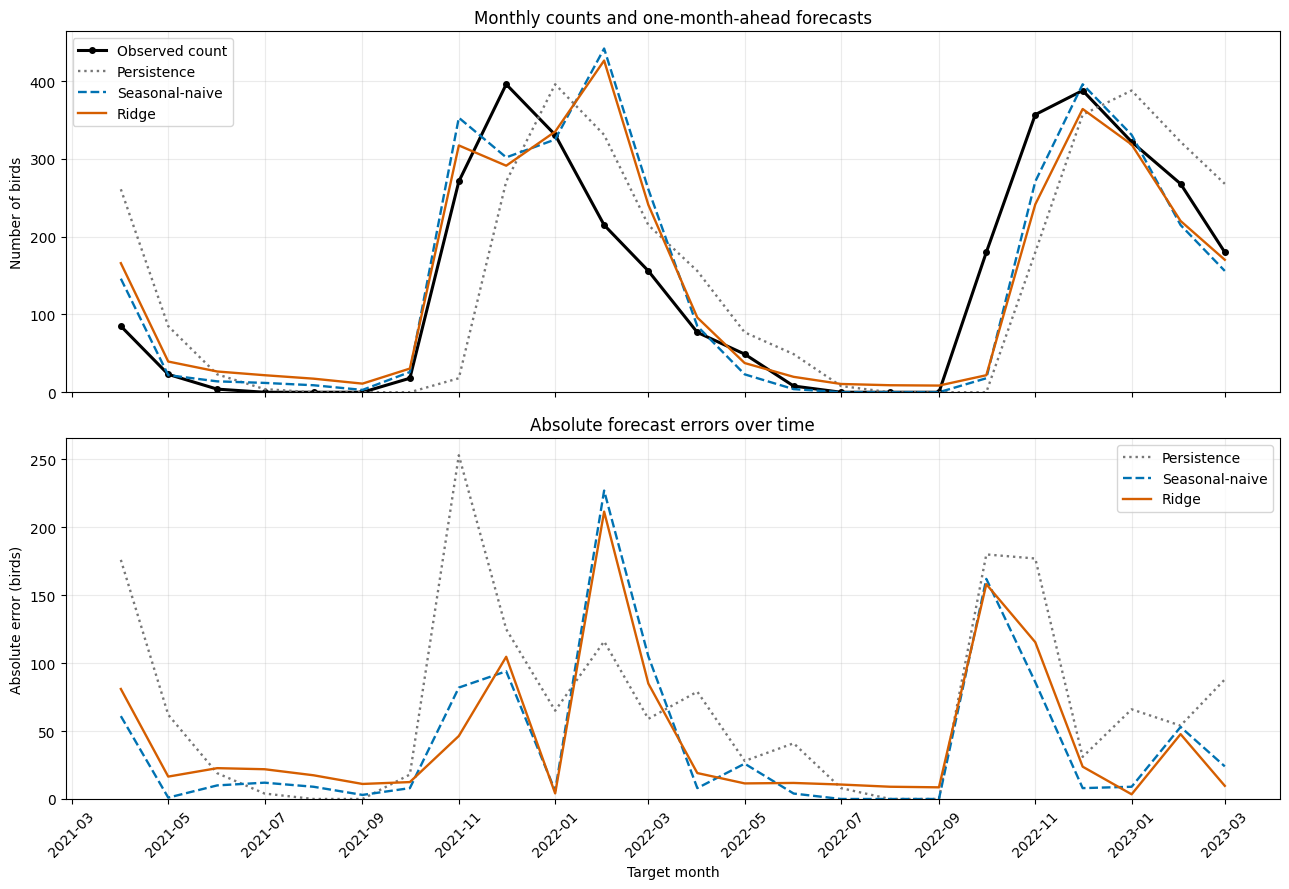

In [8]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Prepare the existing evaluation results for plotting
plot_data = (
    forecast_results
    .sort_values("target_month")
    .copy()
)

assert len(plot_data) == len(rolling_schedule)

# Use consistent colours and labels in both panels
model_styles = {
    "persistence": {
        "label": "Persistence",
        "color": "#777777",
        "linestyle": ":"
    },
    "seasonal_naive": {
        "label": "Seasonal-naive",
        "color": "#0072B2",
        "linestyle": "--"
    },
    "ridge": {
        "label": "Ridge",
        "color": "#D55E00",
        "linestyle": "-"
    }
}

fig, axes = plt.subplots(
    2, 1,
    figsize=(13, 9),
    sharex=True
)

# Upper panel: observed counts and forecasts
axes[0].plot(
    plot_data["target_month"],
    plot_data["target_count"],
    label="Observed count",
    color="black",
    linewidth=2.2,
    marker="o",
    markersize=4
)

for model_name, style in model_styles.items():
    axes[0].plot(
        plot_data["target_month"],
        plot_data[model_name],
        linewidth=1.7,
        **style
    )

axes[0].set_title("Monthly counts and one-month-ahead forecasts")
axes[0].set_ylabel("Number of birds")
axes[0].set_ylim(bottom=0)
axes[0].legend()
axes[0].grid(alpha=0.25)

# Lower panel: absolute forecast errors
for model_name, style in model_styles.items():
    absolute_error = (
        plot_data[model_name] - plot_data["target_count"]
    ).abs()

    axes[1].plot(
        plot_data["target_month"],
        absolute_error,
        linewidth=1.7,
        **style
    )

axes[1].set_title("Absolute forecast errors over time")
axes[1].set_ylabel("Absolute error (birds)")
axes[1].set_xlabel("Target month")
axes[1].set_ylim(bottom=0)
axes[1].legend()
axes[1].grid(alpha=0.25)

# Format the shared time axis
axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(interval=2)
)
axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%Y-%m")
)
axes[1].tick_params(axis="x", labelrotation=45)

fig.tight_layout()

# Save figures for the report
fig.savefig(
    "DS_A5_forecasts_and_errors.png",
    dpi=300,
    bbox_inches="tight"
)
fig.savefig(
    "DS_A5_forecasts_and_errors.pdf",
    bbox_inches="tight"
)

plt.show()

#### Interpretation

Observed counts show a strong seasonal pattern, with high winter counts and low summer counts. Persistence struggles with rapid changes because it carries the previous month's count forward.

Seasonal-naive captures the annual pattern but misses differences between years. For example, it predicts 442 birds for February 2022, compared with 215 observed, and only 18 for October 2022, compared with 180 observed.

Ridge also struggles during these periods and produces positive forecasts during summer months with zero observed counts.

These patterns identify critical periods for further error analysis. They do not, by themselves, establish a persistent change in the data-generating process.

### Critical-period error analysis

Forecast performance is examined within four calendar-based groups: winter (December–February), spring (March–May), summer (June–August), and autumn (September–November).

Each group contains six evaluation months. These groups support exploratory error diagnosis and do not define the species' exact migration periods.

Seasonal metrics and the three largest absolute errors for each method are examined. This analysis does not change the previously specified models or evaluation protocol.

In [9]:
# Add calendar-based diagnostic groups
diagnostics = forecast_results.copy()

season_map = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn"
}

season_order = ["Winter", "Spring", "Summer", "Autumn"]
model_names = ["persistence", "seasonal_naive", "ridge"]

diagnostics["season"] = (
    diagnostics["target_month"].dt.month.map(season_map)
)

# Create one row per method and evaluation month
error_details = diagnostics.melt(
    id_vars=["target_month", TARGET, "season"],
    value_vars=model_names,
    var_name="model",
    value_name="prediction"
)

# Calculate signed, absolute, and squared errors
error_details["error"] = (
    error_details["prediction"] - error_details[TARGET]
)
error_details["absolute_error"] = error_details["error"].abs()
error_details["squared_error"] = error_details["error"].pow(2)

# Summarize performance within each season
slice_scores = (
    error_details
    .groupby(["season", "model"])
    .agg(
        n_forecasts=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean")
    )
    .reset_index()
)

slice_scores["RMSE"] = slice_scores["MSE"].pow(0.5)
slice_scores = slice_scores.drop(columns="MSE")

assert slice_scores["n_forecasts"].eq(6).all()

# Display MAE in a compact comparison table
seasonal_mae = (
    slice_scores
    .pivot(index="season", columns="model", values="MAE")
    .reindex(index=season_order, columns=model_names)
)

print("MAE by calendar season — six forecasts per season:")
display(seasonal_mae.round(2))

# Identify the three largest errors for each method
worst_errors = (
    error_details
    .sort_values("absolute_error", ascending=False)
    .groupby("model", sort=False)
    .head(3)
    .sort_values(
        ["model", "absolute_error"],
        ascending=[True, False]
    )
)

print("\nThree largest absolute errors per method:")
display(
    worst_errors[[
        "model",
        "target_month",
        TARGET,
        "prediction",
        "error",
        "absolute_error"
    ]].round(2)
)

MAE by calendar season — six forecasts per season:


model,persistence,seasonal_naive,ridge
season,,,
Winter,76.17,66.17,65.88
Spring,82.00,37.50,37.11
Summer,12.00,5.83,15.58
Autumn,104.67,56.83,58.66



Three largest absolute errors per method:


,model,target_month,target_count,prediction,error,absolute_error
7,persistence,2021-11-01,271,18.00,-253.00,253.00
18,persistence,2022-10-01,180,0.00,-180.00,180.00
19,persistence,2022-11-01,357,180.00,-177.00,177.00
58,ridge,2022-02-01,215,426.51,211.51,211.51
66,ridge,2022-10-01,180,21.90,-158.10,158.10
67,ridge,2022-11-01,357,241.60,-115.40,115.40
34,seasonal_naive,2022-02-01,215,442.00,227.00,227.00
42,seasonal_naive,2022-10-01,180,18.00,-162.00,162.00
35,seasonal_naive,2022-03-01,156,261.00,105.00,105.00


#### Interpretation of seasonal performance and major errors

Persistence struggled most in autumn and spring, when counts changed rapidly between months. Its largest errors were all autumn underpredictions: carrying forward a low count failed to anticipate the subsequent increase.

Ridge and seasonal-naive performed almost equally in winter and spring. Seasonal-naive was stronger in summer and autumn, while Ridge was the least accurate method in summer. Combining the two lagged counts therefore provided little additional benefit and did not adequately reproduce the near-zero summer counts. The generally smaller summer errors also partly reflect the lower numbers of birds recorded.

Ridge and seasonal-naive shared important failure cases: both overpredicted a winter count and underpredicted an autumn count. This shows that their errors were not consistently in one direction. They captured the broad annual pattern but struggled when a month's count differed substantially from the previous year.

These results identify rapid seasonal transitions and differences between years as important forecasting challenges. However, absolute errors depend on the scale of counts, and each seasonal group contains only six forecasts. The results are descriptive: they neither establish the biological causes of count changes nor demonstrate persistent temporal drift.

### Temporal drift diagnostics

Two complete annual cycles are compared: April 2021–March 2022 and April 2022–March 2023. Comparing periods with the same calendar-month coverage reduces confounding by seasonal composition.

The analysis examines changes in observed counts and forecast MAE. Matching calendar months are also plotted together to identify where the annual patterns differ.

This is an exploratory diagnostic. Differences between two annual cycles alone cannot establish persistent drift.

Observed counts by annual period:


,n_months,mean_count,median_count,zero_counts
evaluation_period,,,,
2021/22,12,124.92,54.0,3
2022/23,12,152.42,128.5,3



MAE by annual period:


evaluation_period,2021/22,2022/23
model,,
persistence,74.75,62.67
seasonal_naive,51.50,31.67
ridge,52.89,35.73


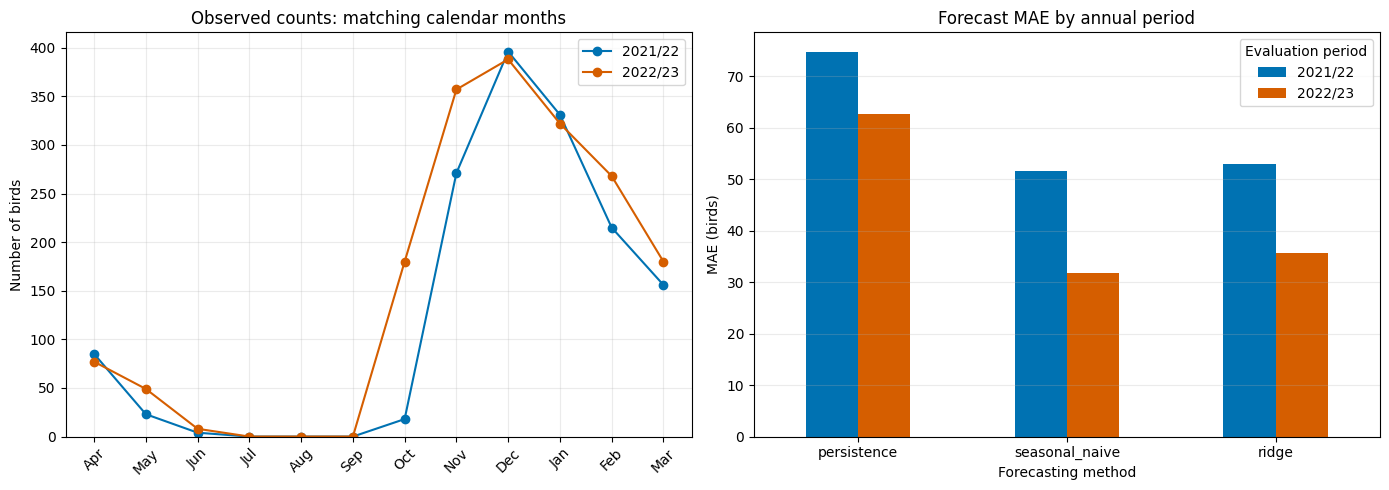

In [10]:
import matplotlib.pyplot as plt

# Define two complete annual evaluation periods
drift_data = forecast_results.copy()

drift_data["evaluation_period"] = np.where(
    drift_data["target_month"] < pd.Timestamp("2022-04-01"),
    "2021/22",
    "2022/23"
)

drift_data["month_number"] = drift_data["target_month"].dt.month

# Confirm that both periods contain all twelve calendar months
months_per_period = (
    drift_data.groupby("evaluation_period")["month_number"].nunique()
)
assert months_per_period.eq(12).all()

# Summarize observed counts in each period
count_summary = (
    drift_data
    .groupby("evaluation_period")
    .agg(
        n_months=(TARGET, "size"),
        mean_count=(TARGET, "mean"),
        median_count=(TARGET, "median"),
        zero_counts=(TARGET, lambda s: s.eq(0).sum())
    )
)

print("Observed counts by annual period:")
display(count_summary.round(2))

# Calculate MAE separately for each method and period
period_score_rows = []

for period, group in drift_data.groupby("evaluation_period"):
    for model_name in ["persistence", "seasonal_naive", "ridge"]:
        absolute_errors = (
            group[model_name] - group[TARGET]
        ).abs()

        period_score_rows.append({
            "evaluation_period": period,
            "model": model_name,
            "MAE": absolute_errors.mean()
        })

period_scores = pd.DataFrame(period_score_rows)

period_mae = (
    period_scores
    .pivot(index="model", columns="evaluation_period", values="MAE")
    .reindex(["persistence", "seasonal_naive", "ridge"])
)

print("\nMAE by annual period:")
display(period_mae.round(2))

# Align observations by calendar month, starting in April
month_order = [4, 5, 6, 7, 8, 9, 10, 11, 12, 1, 2, 3]
month_labels = [
    "Apr", "May", "Jun", "Jul", "Aug", "Sep",
    "Oct", "Nov", "Dec", "Jan", "Feb", "Mar"
]

monthly_comparison = (
    drift_data
    .pivot(
        index="month_number",
        columns="evaluation_period",
        values=TARGET
    )
    .reindex(month_order)
)

# Plot count patterns and forecast performance
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

colours = ["#0072B2", "#D55E00"]

for period, colour in zip(["2021/22", "2022/23"], colours):
    axes[0].plot(
        range(12),
        monthly_comparison[period],
        label=period,
        color=colour,
        marker="o"
    )

axes[0].set_xticks(range(12))
axes[0].set_xticklabels(month_labels, rotation=45)
axes[0].set_title("Observed counts: matching calendar months")
axes[0].set_ylabel("Number of birds")
axes[0].set_ylim(bottom=0)
axes[0].legend()
axes[0].grid(alpha=0.25)

period_mae.plot(
    kind="bar",
    ax=axes[1],
    color=colours,
    rot=0
)

axes[1].set_title("Forecast MAE by annual period")
axes[1].set_xlabel("Forecasting method")
axes[1].set_ylabel("MAE (birds)")
axes[1].legend(title="Evaluation period")
axes[1].grid(axis="y", alpha=0.25)

fig.tight_layout()

fig.savefig("DS_A5_drift_diagnostics.png", dpi=300, bbox_inches="tight")
fig.savefig("DS_A5_drift_diagnostics.pdf", bbox_inches="tight")

plt.show()

#### Interpretation of temporal changes

**Left panel — observed counts.** The broad seasonal pattern is similar in both years: counts are low in summer, increase in autumn, and peak in winter. In the second year, counts are higher particularly in October–November and February–March, while the December peaks are almost identical. The higher average count in the second year therefore reflects changes in particular months rather than a uniform increase throughout the year.

**Right panel — forecast errors.** All three methods have lower MAE in the second year, and seasonal-naive remains the most accurate in both periods. Ridge improves as its training history expands, but the improvement cannot be attributed solely to additional training examples: persistence and seasonal-naive also improve despite having no fitted parameters. The two periods therefore differ in forecasting difficulty as well as in the amount of training data available to Ridge.

The comparison shows differences between annual patterns without a deterioration in overall forecast accuracy. Two annual cycles are insufficient to determine whether the observed changes will persist.

### Monitoring, retraining, and fallback plan

#### Proposed forecasting method

Seasonal-naive is the proposed default method because it achieved the lowest overall MAE and retained this advantage in both annual evaluation periods.

Ridge may continue to run in parallel as a candidate model. Its forecasts should be recorded and evaluated before considering any replacement of the default method.

#### Monthly monitoring

At each forecast origin, the monitoring team should:

- Check the new record for missing values, duplicate months, invalid counts, and changes in survey coverage or methods.
- Preserve genuine zero counts. Missing observations must not be replaced with zeros.
- Record the forecast, issue date, method, and input data version before the next month's count becomes available.
- Once the observed count is available, calculate the signed and absolute forecast errors for each method.

After enough outcomes have accumulated, MAE over the latest twelve months should be compared with MAE over the preceding twelve months. Both windows contain all calendar months, reducing the influence of seasonal composition.

An increase in annual MAE should trigger a review of data quality, survey procedures, and forecasting assumptions. It is a review signal, not proof of drift. Autumn increases and spring decreases should also receive attention because rapid changes can produce large errors.

#### Retraining and model revision

Ridge should be refitted after each new valid monthly observation, using only information available at the next forecast origin. The scaler must also be refitted within the updated training window.

If performance deteriorates, the team should first investigate data and survey changes. Alternative predictors, window lengths, or model settings may then be considered. Revised models must be evaluated at subsequent forecast origins; improvements should not be claimed solely from retuning on the existing evaluation results.

Seasonal-naive requires no parameter fitting, but its annual lag must be updated for each forecast month.

#### Fallback conditions

| Condition | Proposed action |
|---|---|
| The previous year's count for the target month is available and valid | Use seasonal-naive. |
| The annual lag is unavailable, but the latest monthly count is valid | Use persistence temporarily and flag the fallback. |
| Neither required count is available | Withhold the automated forecast and request manual review. |
| Survey coverage or methodology changes substantially | Review comparability before relying on historical forecasting performance. |

These are proposed operating rules. Their effectiveness as a monitoring and fallback system has not been tested in this historical analysis.

### Conclusions and limitations

Monthly counts could be forecast with useful seasonal information, but substantial errors remained during some seasonal transitions and differences between years.

Seasonal-naive achieved the lowest overall MAE (41.58 birds), compared with 44.31 for Ridge. It also retained the lowest MAE in both annual evaluation periods. Combining the latest and previous-year counts through Ridge therefore did not improve the primary metric in this comparison.

Seasonal-naive is the proposed default method for further evaluation. Its performance should continue to be monitored, particularly when recorded counts depart from the previous year's pattern.

The main limitations are:

- The dataset contains only 60 monthly observations, with 24 evaluated forecasts covering two annual cycles. The results do not establish a statistically reliable performance difference or persistent temporal drift.
- The target is a recorded survey count. Detectability, bird movements, survey conditions, and changes in coverage can affect its relationship with the number of birds present.
- Internal month-end availability is assumed. Published counts serve as proxies for internal records; historical release times and revision histories were not verified.
- Only two lagged predictors and one fixed Ridge configuration were tested. The results do not establish that seasonal-naive would outperform every alternative model.
- The monitoring and fallback rules are proposed operating procedures. Their effectiveness has not been tested.